# **Netflix Recommendation Engine**

**What are Recommender Systems?**

Recommender systems are algorithms designed to suggest relevant items to users. These systems are used in various domains such as e-commerce, streaming services, and social media. They enhance user experience by filtering vast amounts of information to deliver personalized content.

#SVD (Singular Value Decomposition) in a recommendation system works by finding patterns in user preferences and item similarities.

Here's a basic idea without going deep into the topic

**1) What the System Has: A big table (matrix) with users on one side and items (like movies) on the other. Users give ratings to items, but not everyone has rated everything**

**2) What SVD Does: SVD looks at the ratings that are available and tries to figure out the hidden connections between users and items. It learns what kind of movies users like based on their previous ratings**

**3) How It Helps: Once SVD understands these patterns, it can predict how a user might rate a movie they haven’t seen yet. Based on these predictions, the system recommends movies that the user is most likely to enjoy**

# How Does SVD Work?

**Imagine you have a big dataset in the form of a matrix. The goal of SVD is to represent this matrix as the product of three simpler matrices:**

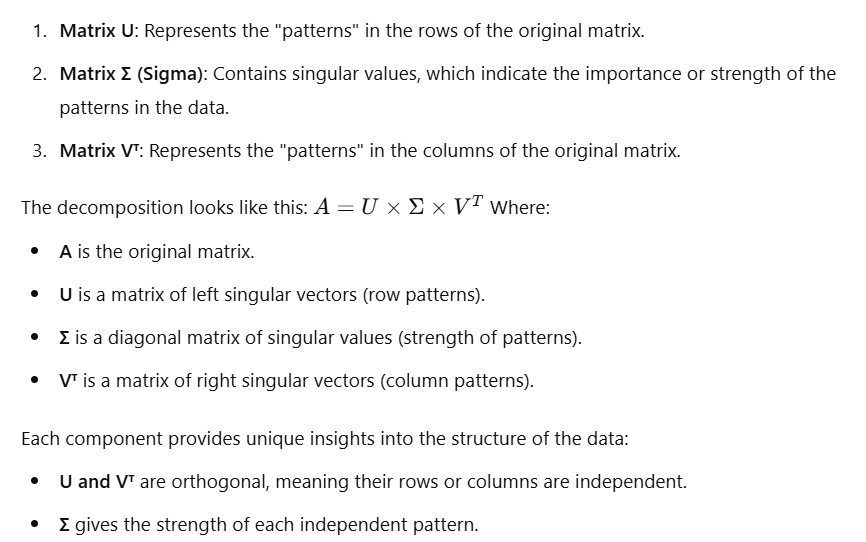

# Step-by-Step Intuition

Let’s use an example of movie ratings to break it down:

Input Matrix: Imagine you have a matrix of users and their ratings for movies. Each cell represents how much a user liked a movie.

**Decomposition:**

U: Groups users into patterns based on their rating preferences (e.g., users who like action movies).

Σ: Identifies how strong or dominant each pattern is (e.g., how many users follow a particular preference).

Vᵀ: Groups movies into patterns based on the ratings they received (e.g., movies in the action genre are liked by similar users).

**Reconstruction:**

 By multiplying U, Σ, and Vᵀ, you can recreate the original matrix. However, you can also keep only the top patterns (largest singular values in Σ) to reduce noise and focus on the most important information.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
netflix_dataset = pd.read_csv("/content/drive/MyDrive/Netflix Dataset/combined_data_1.txt.zip",header=None,names=["CustID","Rating"],usecols=[0,1])
netflix_dataset

,CustID,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


In [ ]:
netflix_dataset.isnull().sum()

,0
CustID,0
Rating,4499


In [ ]:
movie_np = []
movie_id = None
for cust_id in netflix_dataset["CustID"]:
  if ":" in cust_id:
    movie_id = int(cust_id.replace(":",""))
  movie_np.append(movie_id)

In [ ]:
movie_np

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [ ]:
netflix_dataset["MovieID"] = movie_np

In [ ]:
netflix_dataset

,CustID,Rating,MovieID
0,1:,NaN,1
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [ ]:
netflix_dataset.dropna(inplace=True)

In [ ]:
netflix_dataset

,CustID,Rating,MovieID
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [ ]:
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column   Dtype  
---  ------   -----  
 0   CustID   object 
 1   Rating   float64
 2   MovieID  int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 734.1+ MB


In [ ]:
netflix_dataset['CustID'] = netflix_dataset['CustID'].astype(int)

In [ ]:
netflix_dataset.head(3)

,CustID,Rating,MovieID
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1


In [ ]:
netflix_dataset.shape

(24053764, 3)

In [ ]:
#remove movies => that has been rated less
#remove customers => who has given less rating

In [ ]:
movie_summary = netflix_dataset.groupby("MovieID")["Rating"].agg(["count"])

In [ ]:
movie_summary

,count
MovieID,
1,547
2,145
3,2012
4,142
5,1140
...,...
4495,614
4496,9519
4497,714


In [ ]:
movie_benchmark = round(movie_summary['count'].quantile(0.6),0)
movie_benchmark

908.0

In [ ]:
cust_summary = netflix_dataset.groupby("CustID")["Rating"].agg(["count"])

In [ ]:
cust_summary

,count
CustID,
6,153
7,195
8,21
10,49
25,4
...,...
2649404,12
2649409,10
2649421,3


In [ ]:
cust_benchmark = round(cust_summary['count'].quantile(0.6),0)
cust_benchmark

36.0

In [ ]:
drop_movie_list = movie_summary[movie_summary['count']<movie_benchmark].index
drop_cust_list = cust_summary[cust_summary['count']<cust_benchmark].index

In [ ]:
drop_movie_list

Index([   1,    2,    4,    7,    9,   10,   11,   12,   13,   14,
       ...
       4480, 4481, 4486, 4487, 4491, 4494, 4495, 4497, 4498, 4499],
      dtype='int64', name='MovieID', length=2699)

In [ ]:
drop_cust_list

Index([      8,      25,      33,      83,      94,     126,     130,     133,
           142,     149,
       ...
       2649337, 2649343, 2649351, 2649376, 2649379, 2649384, 2649401, 2649404,
       2649409, 2649421],
      dtype='int64', name='CustID', length=282042)

In [ ]:
netflix_dataset = netflix_dataset[~netflix_dataset['MovieID'].isin(drop_movie_list)]
netflix_dataset = netflix_dataset[~netflix_dataset['CustID'].isin(drop_cust_list)]

In [ ]:
netflix_dataset

,CustID,Rating,MovieID
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
700,656399,4.0,3
...,...,...,...
24056842,1055714,5.0,4496
24056843,2643029,4.0,4496
24056844,267802,4.0,4496
24056845,1559566,3.0,4496


In [ ]:
print(np.__version__)

1.26.4


In [ ]:
!pip install numpy==1.26.4

In [ ]:
!pip install surprise

  Using cached surprise-0.1-py2.py3-none-any.whl.metadata (327 bytes)
  Using cached scikit_surprise-1.1.4.tar.gz (154 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp312-cp312-linux_x86_64.whl size=2554989 sha256=20170dc60a2424c5dbae9ddc669238d1358aaf1323c52f6905889041eec2cf2f
  Stored in directory: /root/.cache/pip/wheels/75/fa/bc/739bc2cb1fbaab6061854e6cfbb81a0ae52c92a502a7fa454b
Successfully built scikit-surprise


In [ ]:
import surprise

In [ ]:
from surprise import Reader,Dataset,SVD

In [ ]:
reader = Reader()

In [ ]:
data = Dataset.load_from_df(netflix_dataset[["CustID","MovieID","Rating"]][:1000000],reader)

In [ ]:
data

Model Building recomendation

In [ ]:
from surprise.model_selection import cross_validate

In [ ]:
model = SVD()

In [ ]:
cross_validate(model,data,measures=["RMSE"],cv=3)

{'test_rmse': array([0.9685658 , 0.96834822, 0.96726363]),
 'fit_time': (18.898678064346313, 18.952845335006714, 20.547288417816162),
 'test_time': (4.5472493171691895, 4.436169862747192, 4.630824089050293)}

#Recommendation

In [ ]:
df_titles = pd.read_csv("/content/drive/MyDrive/Netflix Dataset/Copy of movie_titles.csv",encoding="ISO-8859-1",header=None,names=["MovieID","Year","Name"],usecols=[0,1,2])
df_titles

,MovieID,Year,Name
0,1,2003.0,Dinosaur Planet
1,2,2004.0,Isle of Man TT 2004 Review
2,3,1997.0,Character
3,4,1994.0,Paula Abdul's Get Up & Dance
4,5,2004.0,The Rise and Fall of ECW
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
#for whom will i make recommendation?

In [ ]:
#1 recommendation for 1 user?

In [ ]:
netflix_dataset

,CustID,Rating,MovieID
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
700,656399,4.0,3
...,...,...,...
24056842,1055714,5.0,4496
24056843,2643029,4.0,4496
24056844,267802,4.0,4496
24056845,1559566,3.0,4496


In [ ]:
user_1331154 = df_titles.copy()
user_1331154

,MovieID,Year,Name
0,1,2003.0,Dinosaur Planet
1,2,2004.0,Isle of Man TT 2004 Review
2,3,1997.0,Character
3,4,1994.0,Paula Abdul's Get Up & Dance
4,5,2004.0,The Rise and Fall of ECW
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
model.predict(1331154,12)

Prediction(uid=1331154, iid=12, r_ui=None, est=3.762614485633792, details={'was_impossible': False})

In [ ]:
prd_rating = []
for i in user_1331154['MovieID']:
  prediction = model.predict(1331154,i).est
  prd_rating.append(prediction)

In [ ]:
prd_rating

[3.762614485633792,
 3.762614485633792,
 3.9833973638585576,
 3.762614485633792,
 4.207633695771261,
 3.5109253935675557,
 3.762614485633792,
 3.947397630334098,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.0837826627916196,
 2.604475097670652,
 3.8796021488037353,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.0922773858942962,
 3.8658630761732464,
 2.766611793982751,
 3.762614485633792,
 3.8615041440932614,
 3.762614485633792,
 3.731948735666129,
 3.762614485633792,
 4.259820552820433,
 4.43057914919238,
 3.762614485633792,
 3.762614485633792,
 3.3072267678680474,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.762614485633792,
 3.3781526843889176,
 3.0681538783931877,
 4.0018341932529085,
 3.185606071843604,
 3.731360112561752,
 3.762614485633792,
 3.7626144

In [ ]:
user_1331154["PREDICTED_RATING"] = prd_rating
user_1331154

,MovieID,Year,Name,PREDICTED_RATING
0,1,2003.0,Dinosaur Planet,3.762614
1,2,2004.0,Isle of Man TT 2004 Review,3.762614
2,3,1997.0,Character,3.983397
3,4,1994.0,Paula Abdul's Get Up & Dance,3.762614
4,5,2004.0,The Rise and Fall of ECW,4.207634
...,...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...,3.762614
17766,17767,2004.0,Fidel Castro: American Experience,3.762614
17767,17768,2000.0,Epoch,3.762614
17768,17769,2003.0,The Company,3.762614


In [ ]:
user_1331154.sort_values("PREDICTED_RATING",ascending=False).head(15)

,MovieID,Year,Name,PREDICTED_RATING
269,270,2001.0,Sex and the City: Season 4,4.730569
75,76,1952.0,I Love Lucy: Season 2,4.691116
56,57,1995.0,Richard III,4.590482
105,106,2004.0,Stevie Ray Vaughan and Double Trouble: Live at...,4.561721
208,209,1996.0,Star Trek: Deep Space Nine: Season 5,4.464929
214,215,1998.0,That '70s Show: Season 1,4.452404
32,33,2000.0,Aqua Teen Hunger Force: Vol. 1,4.430579
240,241,1959.0,North by Northwest,4.395150
137,138,1995.0,Star Trek: Voyager: Season 1,4.337003
174,175,1992.0,Reservoir Dogs,4.319714
